## 模型消融实验可视化分析

In [16]:
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd

# 路径配置
# 将项目根目录加入 sys.path，以便导入 data_provider / utils
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'run.py').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# 全局字体：Times New Roman（新罗马）。远程系统未安装该字体，需注册项目内的 TTF。
font_manager.fontManager.addfont(PROJECT_ROOT / 'figs/fonts/TIMES.TTF')
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "axes.unicode_minus": False,
    "mathtext.fontset": "stix",
})

EXCEL_PATH = PROJECT_ROOT / 'results/results.xlsx'
EXCEL_SHEET = 'Visual'
SAVE_DIR = PROJECT_ROOT / 'figs'

# 需要绘制的指标列：(均值列, 标准差列, 显示标签)
METRIC_PAIRS = [
    ("F11 Mean", "F11 Std", "Sample-Level F1-score (%)"),
    ("Accuracy1 Mean", "Accuracy1 Std", "Sample-Level Accuracy (%)"),
    ("F12 Mean", "F12 Std", "Subject-Level F1-score (%)"),
    ("Accuracy2 Mean", "Accuracy2 Std", "Subject-Level Accuracy (%)"),
]

# Visual 工作表中模型模块消融数据范围：第 32–70 行（含首尾，1-based；第 1 行为表头）
MODEL_ABLATION_START_ROW = 2
MODEL_ABLATION_END_ROW = 42

# 柱状图 x 轴模块显示名（可按论文需要调整）
MODULE_DISPLAY_LABELS = {
    "Full": "Full Method",
    "noAugmentation": "w/o FBDA",
    "noASB": "w/o ASM",
    "noSamAdaFre": "w/o SAFG",
    "noTSBMB": "w/o BiSTS",
    "noSp": "BiTS",
    "noBi": "STS",
    "noGLP": "w/o PGL",
    "noSamAdaA0": "w/o SAGU",
    "randomA0": "w/o PriorA0",
    "PLI": "PLI Prior",
    "noDifMech": "w/o RGDI",
    "MAMBAminusGCN": "ReRGDI",
    "noComLoss": "w/o HDCL",
    "noLayCon": "w/o HL",
    "noWarmup": "w/o Warmup",
    "noDownSam": "w/o DownSample",
}

# 柱状图配色：Full Model 用 lightcoral，其余消融模块用 lightblue
FULL_MODEL_COLOR = "lightcoral"
ABLATION_BAR_COLOR = "lightblue"
BAR_FACE_ALPHA = 0.7

# 柱状图仅显示以下模块，并按此列表顺序排列
MODULE_ORDER = [
    "Full",
    "noAugmentation",
    "noASB",
    "noSamAdaFre",
    "noTSBMB",
    "noSp",
    "noBi",
    "noGLP",
    "noSamAdaA0",
    "randomA0",
    "PLI",
    "noDifMech",
    "MAMBAminusGCN",
    "noComLoss",
    "noLayCon",
    "noWarmup",
    "noDownSam",
]

# Subject-Level 指标（F12、Accuracy2）
SUBJECT_LEVEL_METRICS = METRIC_PAIRS[2:]

In [17]:
def parse_classification_task(model_name: str) -> str | None:
    """从模型名中提取分类任务：NCvsMCI 或 NCvsMCIvsAD。"""
    name = str(model_name)
    if "NCvsMCIvsAD" in name:
        return "NCvsMCIvsAD"
    if "NCvsMCI" in name:
        return "NCvsMCI"
    return None


def parse_removed_module(model_name: str) -> str | None:
    """
    从模型名中解析被去掉的模块标识。
    - 完整模型：以 oneFreBanDAGnoRanCrop 结尾 -> 'Full'
    - 模块消融：...-oneFreBanDAGnoRanCrop-<module> -> '<module>'
      例如 noASB、randomA0、MAMBAminusGCN
    - 数据增强消融：...-noAugmentation -> 'noAugmentation'
    """
    name = str(model_name).strip()
    if "noAugmentation" in name:
        return "noAugmentation"
    if re.search(r"-oneFreBanDAGnoRanCrop(?:-\d+)?$", name):
        return "Full"
    match = re.search(r"-oneFreBanDAGnoRanCrop-(\w+)$", name)
    return match.group(1) if match else None


def module_display_label(module_key: str) -> str:
    return MODULE_DISPLAY_LABELS.get(module_key, module_key)


def load_model_ablation_results(
    excel_path: str,
    *,
    start_row: int = MODEL_ABLATION_START_ROW,
    end_row: int = MODEL_ABLATION_END_ROW,
    sheet_name: str = EXCEL_SHEET,
) -> pd.DataFrame:
    """读取 Visual 工作表中模型消融部分（start_row–end_row，含首尾，1-based Excel 行号）。"""
    df = pd.read_excel(excel_path, sheet_name=sheet_name)
    df = df.rename(columns={df.columns[0]: "model"})
    # read_excel(header=0) 时，Excel 第 N 行对应 iloc[N - 2]
    df = df.iloc[start_row - 2 : end_row - 1].copy()
    df = df.dropna(subset=["model"])
    df["model"] = df["model"].astype(str)
    df["task"] = df["model"].map(parse_classification_task)
    df["module"] = df["model"].map(parse_removed_module)
    df = df.dropna(subset=["task", "module"])
    return df.reset_index(drop=True)


def filter_model_ablation(df: pd.DataFrame, task: str) -> pd.DataFrame:
    """按分类任务筛选，仅保留 MODULE_ORDER 中的模块并按其顺序排列。"""
    subset = df[(df["task"] == task) & (df["module"].isin(MODULE_ORDER))].copy()
    order_map = {key: idx for idx, key in enumerate(MODULE_ORDER)}
    subset["sort_key"] = subset["module"].map(order_map)
    subset = subset.sort_values("sort_key").reset_index(drop=True)
    return subset.drop(columns="sort_key")


def _format_mean_std_label(mean: float, std: float, *, value_fmt: str = ".2f", as_percent: bool = True) -> str:
    if as_percent:
        mean, std = mean * 100, std * 100
    return f"{format(mean, value_fmt)}\n±{format(std, value_fmt)}"


def module_bar_color(module_key: str) -> str:
    """Full Model 用 lightcoral，其余消融模块用 lightblue。"""
    return FULL_MODEL_COLOR if module_key == "Full" else ABLATION_BAR_COLOR


def _full_model_baseline_y(
    data: pd.DataFrame,
    mean_col: str,
    *,
    value_as_percent: bool = True,
) -> float | None:
    """返回 Full Model 对应指标的均值（绘图坐标系下的 y 值）。"""
    full = data.loc[data["module"] == "Full", mean_col]
    if full.empty:
        return None
    val = float(full.iloc[0])
    return val * 100 if value_as_percent else val


def _add_full_model_baseline(
    ax,
    baseline_y: float | None,
    *,
    linewidth: float = 1.5,
    alpha: float = 1.0,
) -> None:
    """在子图中绘制 Full Model 均值基准虚线。"""
    if baseline_y is None:
        return
    ax.axhline(
        baseline_y,
        color=FULL_MODEL_COLOR,
        linewidth=linewidth,
        linestyle="--",
        alpha=alpha,
        zorder=4,
    )


def _resolve_metric_ymin(
    mean_col: str,
    metric_label: str,
    *,
    metric_ymin: dict[str, float] | None,
    f1_ymin: float | None,
    accuracy_ymin: float | None,
    sample_level_ymin: float,
    subject_level_ymin: float,
    value_as_percent: bool,
) -> float:
    """按 mean 列名解析纵轴下限；metric_ymin 优先，其次 f1_ymin / accuracy_ymin。"""
    raw: float | None = None
    if metric_ymin and mean_col in metric_ymin:
        raw = metric_ymin[mean_col]
    elif mean_col in ("F11 Mean", "F12 Mean") and f1_ymin is not None:
        raw = f1_ymin
    elif mean_col in ("Accuracy1 Mean", "Accuracy2 Mean") and accuracy_ymin is not None:
        raw = accuracy_ymin
    elif "Sample-Level" in metric_label:
        raw = sample_level_ymin
    elif "Subject-Level" in metric_label:
        raw = subject_level_ymin
    else:
        raw = 0
    return raw if value_as_percent else raw / 100


def _resolve_metric_ymax(
    mean_col: str,
    *,
    metric_ymax: dict[str, float] | None,
    auto_ymax: float,
    value_as_percent: bool,
) -> float:
    """按 mean 列名解析纵轴上限；未指定时使用 auto_ymax。"""
    if metric_ymax and mean_col in metric_ymax:
        raw = metric_ymax[mean_col]
        return raw if value_as_percent else raw / 100
    return auto_ymax


def plot_model_ablation_bars(
    df: pd.DataFrame,
    metric_pairs: list[tuple[str, str, str]],
    save_dir: str,
    *,
    task: str = "NCvsMCI",
    task_title: str | None = None,
    dataset_name: str = "CAEEG",
    figsize=(24, 5),
    dpi=600,
    bar_alpha: float = BAR_FACE_ALPHA,
    title_fontsize: float = 14,
    xlabel_fontsize: float = 11,
    ylabel_fontsize: float = 12,
    xtick_fontsize: float = 9,
    ytick_fontsize: float = 10,
    annotate_values: bool = True,
    value_fmt: str = ".2f",
    value_as_percent: bool = True,
    value_fontsize: float = 8,
    rotation: float = 45,
    ha: str = "right",
    metric_ymin: dict[str, float] | None = None,
    metric_ymax: dict[str, float] | None = None,
    f1_ymin: float | None = None,
    accuracy_ymin: float | None = None,
    sample_level_ymin: float = 50,
    subject_level_ymin: float = 40,
    ymax_pad_ratio: float = 0.05,
    label_offset_ratio: float = 0.03,
    baseline_linewidth: float = 1.5,
    baseline_alpha: float = 1.0,
    show_preview: bool = True,
):
    """
    绘制模型模块消融柱状图（含标准差误差线）。
    每个指标一个子图，x 轴为去掉的模块，y 轴为对应指标得分。

    字体大小参数:
    - title_fontsize: 总标题
    - ylabel_fontsize: 纵轴标题（指标名）
    - xtick_fontsize / ytick_fontsize: 横/纵坐标刻度
    - value_fontsize: 柱顶 mean±std 标注

    纵轴范围（value_as_percent=True 时单位为 %，优先级从高到低）:
    - metric_ymin: 按 mean 列名分别指定下限，如 {"F11 Mean": 35, "Accuracy1 Mean": 50, ...}
    - metric_ymax: 按 mean 列名分别指定上限；未指定时由数据与 ymax_pad_ratio 自动计算
    - f1_ymin: F11 / F12 共用下限
    - accuracy_ymin: Accuracy1 / Accuracy2 共用下限
    - sample_level_ymin / subject_level_ymin: 上述未设置时的兜底（按 Sample/Subject-Level）
    - ymax_pad_ratio: 纵轴上限相对数据跨度的额外留白比例（metric_ymax 未指定时生效）
    - label_offset_ratio: 标注文字相对数据跨度的上移比例

    Full Model 基准线:
    - baseline_linewidth: 基准虚线线宽
    - baseline_alpha: 基准虚线透明度

    预览:
    - show_preview: 是否在 Notebook 输出区 / 终端中显示图片
    """
    data = filter_model_ablation(df, task)
    if data.empty:
        raise ValueError(f"未找到任务 '{task}' 的模型消融数据")

    if task_title is None:
        task_title = "NC vs MCI" if task == "NCvsMCI" else "NC vs MCI vs AD"

    n_cols = len(metric_pairs)
    fig, axes = plt.subplots(1, n_cols, figsize=figsize, sharey=False)
    if n_cols == 1:
        axes = [axes]

    for ax, (mean_col, std_col, metric_label), color_unused in zip(axes, metric_pairs, range(n_cols)):
        _plot_ablation_bars_on_ax(
            ax,
            data,
            mean_col,
            std_col,
            metric_label,
            bar_alpha=bar_alpha,
            annotate_values=annotate_values,
            value_fmt=value_fmt,
            value_as_percent=value_as_percent,
            value_fontsize=value_fontsize,
            xtick_fontsize=xtick_fontsize,
            ytick_fontsize=ytick_fontsize,
            ylabel_fontsize=ylabel_fontsize,
            rotation=rotation,
            ha=ha,
            metric_ymin=metric_ymin,
            metric_ymax=metric_ymax,
            f1_ymin=f1_ymin,
            accuracy_ymin=accuracy_ymin,
            sample_level_ymin=sample_level_ymin,
            subject_level_ymin=subject_level_ymin,
            ymax_pad_ratio=ymax_pad_ratio,
            label_offset_ratio=label_offset_ratio,
            baseline_linewidth=baseline_linewidth,
            baseline_alpha=baseline_alpha,
        )

    fig.suptitle(f"{dataset_name} Model Ablation — {task_title}", fontsize=title_fontsize, y=1.02)
    fig.tight_layout()

    save_path = Path(save_dir)
    save_path.mkdir(parents=True, exist_ok=True)
    out_file = save_path / f"{dataset_name}_ModelAblation_{task}_bar.png"
    fig.savefig(out_file, dpi=dpi, bbox_inches="tight")
    print(f"已保存: {out_file}")

    if show_preview:
        try:
            from IPython.display import display
            display(fig)
        except ImportError:
            plt.show()

    plt.close(fig)
    return out_file


def _plot_ablation_bars_on_ax(
    ax,
    data: pd.DataFrame,
    mean_col: str,
    std_col: str,
    metric_label: str,
    *,
    bar_alpha: float = BAR_FACE_ALPHA,
    annotate_values: bool = True,
    value_fmt: str = ".2f",
    value_as_percent: bool = True,
    value_fontsize: float = 8,
    xtick_fontsize: float = 9,
    ytick_fontsize: float = 10,
    ylabel_fontsize: float = 12,
    rotation: float = 45,
    ha: str = "right",
    metric_ymin: dict[str, float] | None = None,
    metric_ymax: dict[str, float] | None = None,
    f1_ymin: float | None = None,
    accuracy_ymin: float | None = None,
    sample_level_ymin: float = 50,
    subject_level_ymin: float = 40,
    ymax_pad_ratio: float = 0.05,
    label_offset_ratio: float = 0.03,
    bar_width: float = 0.72,
    bar_gap: float = 0.28,
    bar_side_margin: float = 0.84,
    baseline_linewidth: float = 1.5,
    baseline_alpha: float = 1.0,
):
    """在指定 axes 上绘制单个指标的模型消融柱状图。

    bar_gap: 相邻柱之间的空白间隔（与柱宽同一坐标单位）。
    bar_side_margin: 最左/最右柱外侧到左右坐标轴边界的距离。
    """
    labels = [module_display_label(m) for m in data["module"]]
    pitch = bar_width + bar_gap
    x = np.arange(len(labels)) * pitch
    colors = [module_bar_color(m) for m in data["module"]]

    means = data[mean_col].astype(float).values
    stds = data[std_col].astype(float).values
    plot_means = means * 100 if value_as_percent else means
    plot_stds = stds * 100 if value_as_percent else stds

    bars = ax.bar(
        x,
        plot_means,
        yerr=plot_stds,
        capsize=4,
        color=colors,
        alpha=bar_alpha,
        edgecolor="black",
        linewidth=0.6,
        error_kw={"elinewidth": 1.2, "ecolor": "black", "capthick": 1.2},
        width=bar_width,
        zorder=3,
    )
    if len(x) > 0:
        half = bar_width / 2
        ax.set_xlim(x[0] - half - bar_side_margin, x[-1] + half + bar_side_margin)

    ymin = _resolve_metric_ymin(
        mean_col,
        metric_label,
        metric_ymin=metric_ymin,
        f1_ymin=f1_ymin,
        accuracy_ymin=accuracy_ymin,
        sample_level_ymin=sample_level_ymin,
        subject_level_ymin=subject_level_ymin,
        value_as_percent=value_as_percent,
    )

    plot_means_arr = np.asarray(plot_means, dtype=float)
    plot_stds_arr = np.asarray(plot_stds, dtype=float)
    data_top = float(np.max(plot_means_arr + plot_stds_arr))
    data_span = max(data_top - ymin, 1.0)
    label_offset = max(data_span * label_offset_ratio, 0.35 if value_as_percent else 0.0035)

    if annotate_values:
        for bar, mean_val, std_val in zip(bars, means, stds):
            err_top = bar.get_height() + (std_val * 100 if value_as_percent else std_val)
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                err_top + label_offset,
                _format_mean_std_label(mean_val, std_val, value_fmt=value_fmt, as_percent=value_as_percent),
                ha="center",
                va="bottom",
                fontsize=value_fontsize,
                rotation=0,
            )
        label_tops = plot_means_arr + plot_stds_arr + label_offset
        ymax = float(np.max(label_tops)) + max(data_span * ymax_pad_ratio, 0.6 if value_as_percent else 0.006)
    else:
        ymax = data_top + data_span * ymax_pad_ratio

    ymax = _resolve_metric_ymax(
        mean_col,
        metric_ymax=metric_ymax,
        auto_ymax=ymax,
        value_as_percent=value_as_percent,
    )

    _add_full_model_baseline(
        ax,
        _full_model_baseline_y(data, mean_col, value_as_percent=value_as_percent),
        linewidth=baseline_linewidth,
        alpha=baseline_alpha,
    )

    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=rotation, ha=ha, fontsize=xtick_fontsize)
    ax.set_ylabel(metric_label, fontsize=ylabel_fontsize)
    ax.tick_params(axis="y", labelsize=ytick_fontsize)
    ax.grid(True, axis="y", linestyle="--", alpha=0.35, zorder=0)
    ax.set_axisbelow(True)
    ax.set_ylim(ymin, ymax)


def plot_subject_level_task_panel(
    df: pd.DataFrame,
    save_dir: str,
    *,
    tasks: tuple[str, str] = ("NCvsMCI", "NCvsMCIvsAD"),
    row_titles: tuple[str, str] | None = None,
    metric_pairs: list[tuple[str, str, str]] | None = None,
    dataset_name: str = "USTBMCI",
    figure_title: str | None = None,
    metric_ymin_by_task: dict[str, dict[str, float]] | None = None,
    metric_ymax_by_task: dict[str, dict[str, float]] | None = None,
    metric_ymin: dict[str, float] | None = None,
    metric_ymax: dict[str, float] | None = None,
    figsize=(14, 10),
    dpi=600,
    bar_alpha: float = BAR_FACE_ALPHA,
    title_fontsize: float = 14,
    ylabel_fontsize: float = 12,
    xtick_fontsize: float = 9,
    ytick_fontsize: float = 10,
    annotate_values: bool = True,
    value_fmt: str = ".2f",
    value_as_percent: bool = True,
    value_fontsize: float = 8,
    rotation: float = 45,
    ha: str = "right",
    f1_ymin: float | None = None,
    accuracy_ymin: float | None = None,
    sample_level_ymin: float = 50,
    subject_level_ymin: float = 40,
    ymax_pad_ratio: float = 0.05,
    label_offset_ratio: float = 0.03,
    bar_gap: float = 0.28,
    bar_side_margin: float = 0.84,
    baseline_linewidth: float = 1.5,
    baseline_alpha: float = 1.0,
    row_title_pad: float = 0.02,
    hspace: float = 0.45,
    show_preview: bool = True,
):
    """
    2×2 分面板：上排为 tasks[0]（二分类），下排为 tasks[1]（三分类）。
    每行绘制 Subject-Level 指标（F12、Accuracy2）的模型消融柱状图。

    metric_ymin_by_task / metric_ymax_by_task: 按任务分别指定纵轴下限/上限，例如
        {"NCvsMCI": {"F12 Mean": 40, "Accuracy2 Mean": 40}, ...}
    metric_ymin / metric_ymax: 所有任务共用的纵轴下限/上限（可被 *_by_task 覆盖）
    baseline_linewidth / baseline_alpha: Full Model 基准虚线的线宽与透明度
    bar_gap: 相邻柱之间的空白间隔（柱宽默认 0.72，间隔越大柱越疏）
    bar_side_margin: 最左/最右柱外侧到左右坐标轴边界的距离，越大两侧留白越多
    show_preview: 是否在 Notebook 输出区 / 终端中显示图片
    """
    if metric_pairs is None:
        metric_pairs = SUBJECT_LEVEL_METRICS
    if len(metric_pairs) != 2:
        raise ValueError("metric_pairs 需包含两个 Subject-Level 指标：(F12, Accuracy2)")
    if row_titles is None:
        row_titles = ("NC vs MCI", "NC vs MCI vs AD")

    save_path = Path(save_dir)
    save_path.mkdir(parents=True, exist_ok=True)

    fig, axes = plt.subplots(2, 2, figsize=figsize)
    for row, task in enumerate(tasks):
        data = filter_model_ablation(df, task)
        if data.empty:
            raise ValueError(f"未找到任务 '{task}' 的模型消融数据")

        task_metric_ymin = metric_ymin
        if metric_ymin_by_task and task in metric_ymin_by_task:
            task_metric_ymin = metric_ymin_by_task[task]

        task_metric_ymax = metric_ymax
        if metric_ymax_by_task and task in metric_ymax_by_task:
            task_metric_ymax = metric_ymax_by_task[task]

        for col, (mean_col, std_col, metric_label) in enumerate(metric_pairs):
            _plot_ablation_bars_on_ax(
                axes[row, col],
                data,
                mean_col,
                std_col,
                metric_label,
                bar_alpha=bar_alpha,
                annotate_values=annotate_values,
                value_fmt=value_fmt,
                value_as_percent=value_as_percent,
                value_fontsize=value_fontsize,
                xtick_fontsize=xtick_fontsize,
                ytick_fontsize=ytick_fontsize,
                ylabel_fontsize=ylabel_fontsize,
                rotation=rotation,
                ha=ha,
                metric_ymin=task_metric_ymin,
                metric_ymax=task_metric_ymax,
                f1_ymin=f1_ymin,
                accuracy_ymin=accuracy_ymin,
                sample_level_ymin=sample_level_ymin,
                subject_level_ymin=subject_level_ymin,
                ymax_pad_ratio=ymax_pad_ratio,
                label_offset_ratio=label_offset_ratio,
                bar_gap=bar_gap,
                bar_side_margin=bar_side_margin,
                baseline_linewidth=baseline_linewidth,
                baseline_alpha=baseline_alpha,
            )

    if figure_title is not None:
        fig.suptitle(figure_title, fontsize=title_fontsize, y=1.02)

    fig.tight_layout()
    fig.subplots_adjust(hspace=hspace)
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()

    def _row_extent(row_axes):
        bboxes = [
            ax.get_tightbbox(renderer).transformed(fig.transFigure.inverted())
            for ax in row_axes
        ]
        return (
            min(b.x0 for b in bboxes),
            max(b.x1 for b in bboxes),
            min(b.y0 for b in bboxes),
            max(b.y1 for b in bboxes),
        )

    x0_r0, x1_r0, _, y1_r0 = _row_extent(axes[0])
    fig.text(
        (x0_r0 + x1_r0) / 2,
        y1_r0 + row_title_pad,
        row_titles[0],
        ha="center",
        va="bottom",
        fontsize=title_fontsize,
    )

    _, _, y0_r0, _ = _row_extent(axes[0])
    x0_r1, x1_r1, _, y1_r1 = _row_extent(axes[1])
    fig.text(
        (x0_r1 + x1_r1) / 2,
        (y0_r0 + y1_r1) / 2,
        row_titles[1],
        ha="center",
        va="center",
        fontsize=title_fontsize,
    )

    out_file = save_path / (
        f"{dataset_name}_ModelAblation_SubjectLevel_{tasks[0]}_vs_{tasks[1]}_panel.svg"
    )
    fig.savefig(out_file, format='svg', bbox_inches='tight', facecolor='white')
    print(f"已保存: {out_file}")

    if show_preview:
        try:
            from IPython.display import display
            display(fig)
        except ImportError:
            plt.show()

    plt.close(fig)
    return out_file

二分类消融模型：
                                                                                                                                                                       model         module
              USTBMCI3_1s_00_EO_Aug-ADMamba-lare10-drop07-pat15-warEp05-embDim32-proDim128-supConNoUni-subInvertsamLab-preOneLin-proD-LEB8-Res-NCvsMCI-oneFreBanDAGnoRanCrop           Full
                     USTBMCI3_1s_00_EO_Aug-ADMamba-lare10-drop07-pat15-warEp05-embDim32-proDim128-supConNoUni-subInvertsamLab-preOneLin-proD-LEB8-Res-NCvsMCI-noAugmentation noAugmentation
        USTBMCI3_1s_00_EO_Aug-ADMamba-lare10-drop07-pat15-warEp05-embDim32-proDim128-supConNoUni-subInvertsamLab-preOneLin-proD-LEB8-Res-NCvsMCI-oneFreBanDAGnoRanCrop-noASB          noASB
  USTBMCI3_1s_00_EO_Aug-ADMamba-lare10-drop07-pat15-warEp05-embDim32-proDim128-supConNoUni-subInvertsamLab-preOneLin-proD-LEB8-Res-NCvsMCI-oneFreBanDAGnoRanCrop-noSamAdaFre    noSamAdaFre
      USTBMCI3_1s_00_EO_Aug-ADMamba-lare10-drop07-p

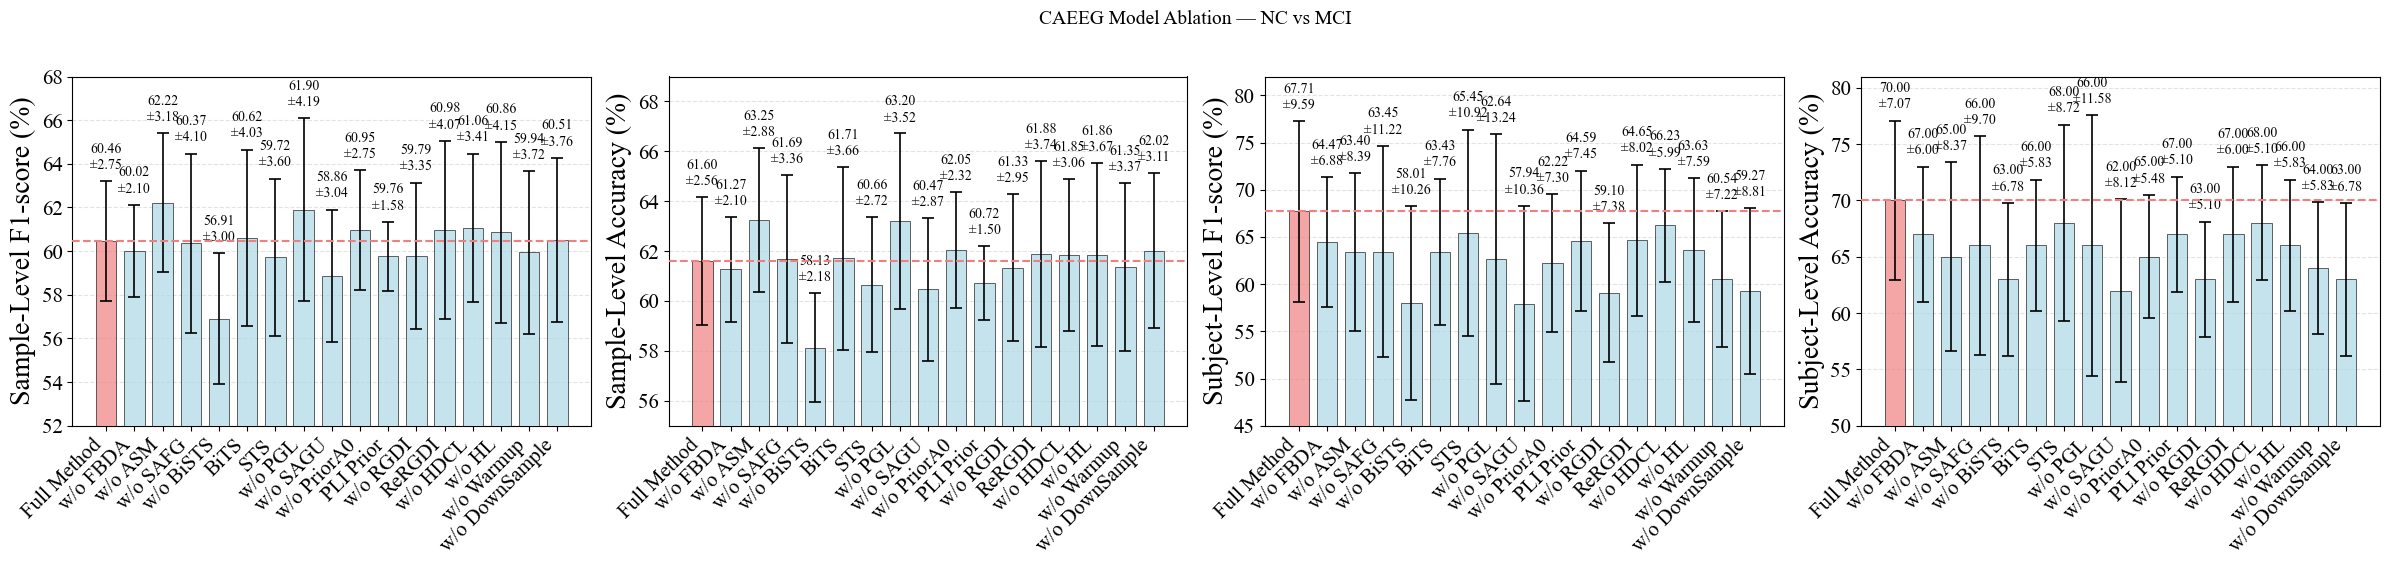

PosixPath('/root/autodl-tmp/ADSST-Net/figs/CAEEG_ModelAblation_NCvsMCI_bar.png')

In [18]:
# 二分类（NC vs MCI）模型模块消融柱状图
df_ablation = load_model_ablation_results(EXCEL_PATH)
print("二分类消融模型：")
print(filter_model_ablation(df_ablation, "NCvsMCI")[["model", "module"]].to_string(index=False))

plot_model_ablation_bars(
    df_ablation,
    metric_pairs=METRIC_PAIRS,
    save_dir=SAVE_DIR,
    task="NCvsMCI",
    task_title="NC vs MCI",
    figsize=(24, 5.5),
    rotation=45,
    value_fmt=".2f",
    value_as_percent=True,
    # 字体大小（可按需调整）
    title_fontsize=14, # 图总标题
    ylabel_fontsize=20, # 纵轴标题（指标名）
    xtick_fontsize=15, # 横轴模块名刻度
    ytick_fontsize=15, # 纵轴数值刻度
    value_fontsize=10, # 柱顶 mean±std 标注
    # 纵轴范围（value_as_percent=True 时单位为 %；上限未指定时自动计算）
    metric_ymin={
        "F11 Mean": 52,
        "Accuracy1 Mean": 55,
        "F12 Mean": 45,
        "Accuracy2 Mean": 50,
    },
    metric_ymax={
        "F11 Mean": 68,
        "Accuracy1 Mean": 69,
        "F12 Mean": 82,
        "Accuracy2 Mean": 81,
    },
    # Full Model 基准虚线（可按需调整）
    baseline_linewidth=1.5,
    baseline_alpha=1.0,
)

三分类消融模型：
                                                                                                                                                                           model         module
              USTBMCI3_1s_00_EO_Aug-ADMamba-lare10-drop07-pat15-warEp05-embDim32-proDim128-supConNoUni-subInvertsamLab-preOneLin-proD-LEB8-Res-NCvsMCIvsAD-oneFreBanDAGnoRanCrop           Full
                     USTBMCI3_1s_00_EO_Aug-ADMamba-lare10-drop07-pat15-warEp05-embDim32-proDim128-supConNoUni-subInvertsamLab-preOneLin-proD-LEB8-Res-NCvsMCIvsAD-noAugmentation noAugmentation
        USTBMCI3_1s_00_EO_Aug-ADMamba-lare10-drop07-pat15-warEp05-embDim32-proDim128-supConNoUni-subInvertsamLab-preOneLin-proD-LEB8-Res-NCvsMCIvsAD-oneFreBanDAGnoRanCrop-noASB          noASB
  USTBMCI3_1s_00_EO_Aug-ADMamba-lare10-drop07-pat15-warEp05-embDim32-proDim128-supConNoUni-subInvertsamLab-preOneLin-proD-LEB8-Res-NCvsMCIvsAD-oneFreBanDAGnoRanCrop-noSamAdaFre    noSamAdaFre
      USTBMCI3_1s_00_EO_Aug-ADM

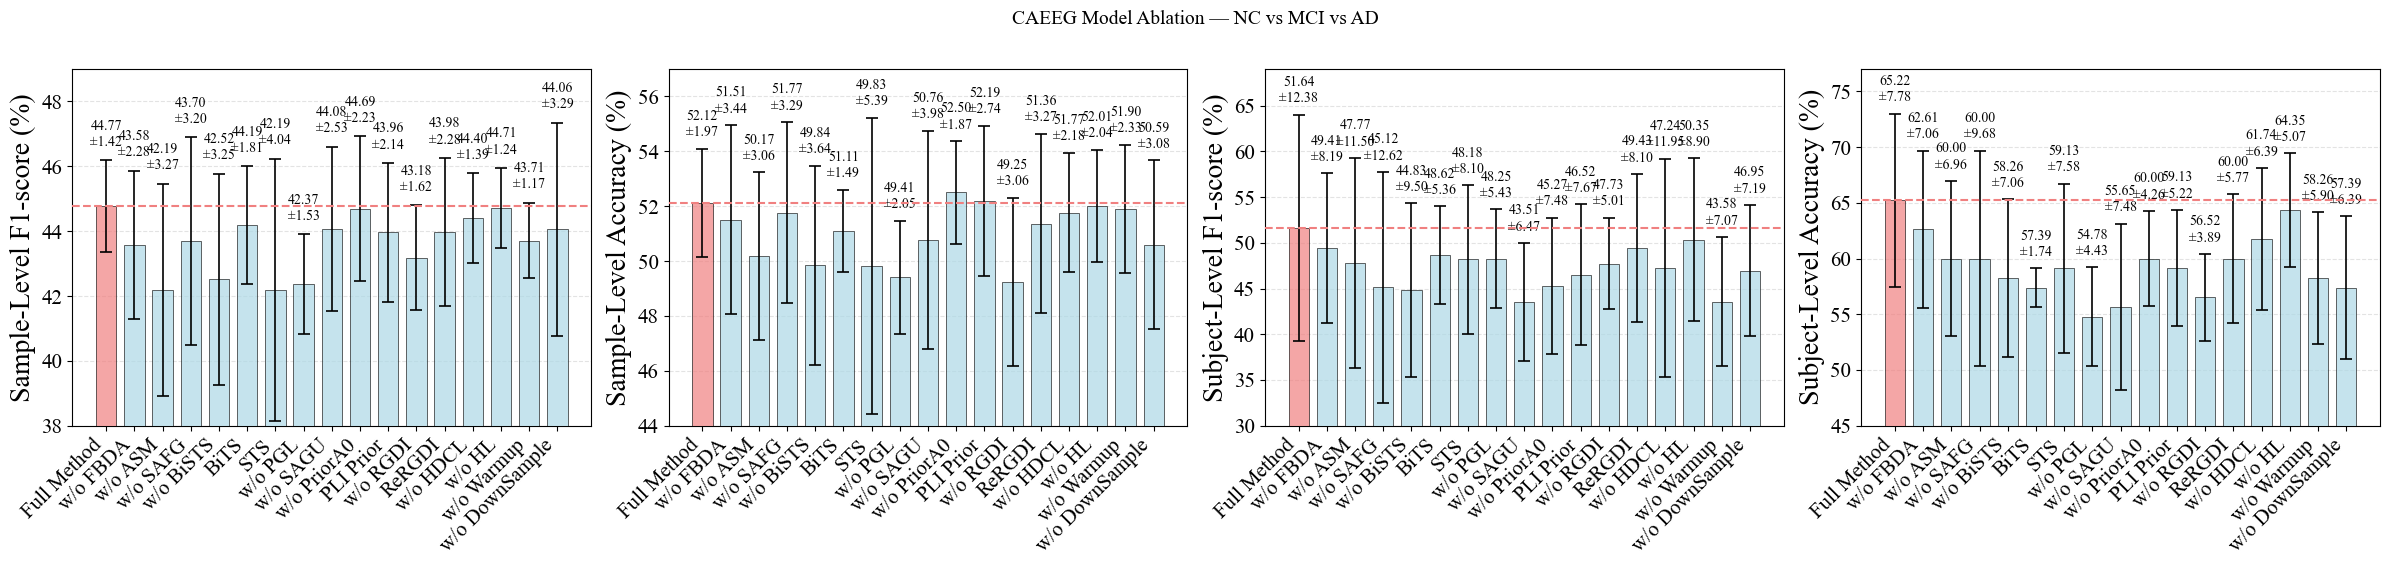

PosixPath('/root/autodl-tmp/ADSST-Net/figs/CAEEG_ModelAblation_NCvsMCIvsAD_bar.png')

In [19]:
# 三分类（NC vs MCI vs AD）模型模块消融柱状图
if "df_ablation" not in globals():
    df_ablation = load_model_ablation_results(EXCEL_PATH)
print("三分类消融模型：")
print(filter_model_ablation(df_ablation, "NCvsMCIvsAD")[["model", "module"]].to_string(index=False))

plot_model_ablation_bars(
    df_ablation,
    metric_pairs=METRIC_PAIRS,
    save_dir=SAVE_DIR,
    task="NCvsMCIvsAD",
    task_title="NC vs MCI vs AD",
    figsize=(24, 5.5),
    rotation=45,
    value_fmt=".2f",
    value_as_percent=True,
    # 字体大小（可按需调整）
    title_fontsize=14,  # 图总标题
    ylabel_fontsize=20,  # 纵轴标题（指标名）
    xtick_fontsize=15,  # 横轴模块名刻度
    ytick_fontsize=15,  # 纵轴数值刻度
    value_fontsize=10,  # 柱顶 mean±std 标注
    # 纵轴范围（value_as_percent=True 时单位为 %；上限未指定时自动计算）
    metric_ymin={
        "F11 Mean": 38,
        "Accuracy1 Mean": 44,
        "F12 Mean": 30,
        "Accuracy2 Mean": 45,
    },
    metric_ymax={
        "F11 Mean": 49,
        "Accuracy1 Mean": 57,
        "F12 Mean": 69,
        "Accuracy2 Mean": 77,
    },
    # Full Model 基准虚线（可按需调整）
    baseline_linewidth=1.5,
    baseline_alpha=1.0,
)

已保存: /root/autodl-tmp/ADSST-Net/figs/USTBMCI_ModelAblation_SubjectLevel_NCvsMCI_vs_NCvsMCIvsAD_panel.svg


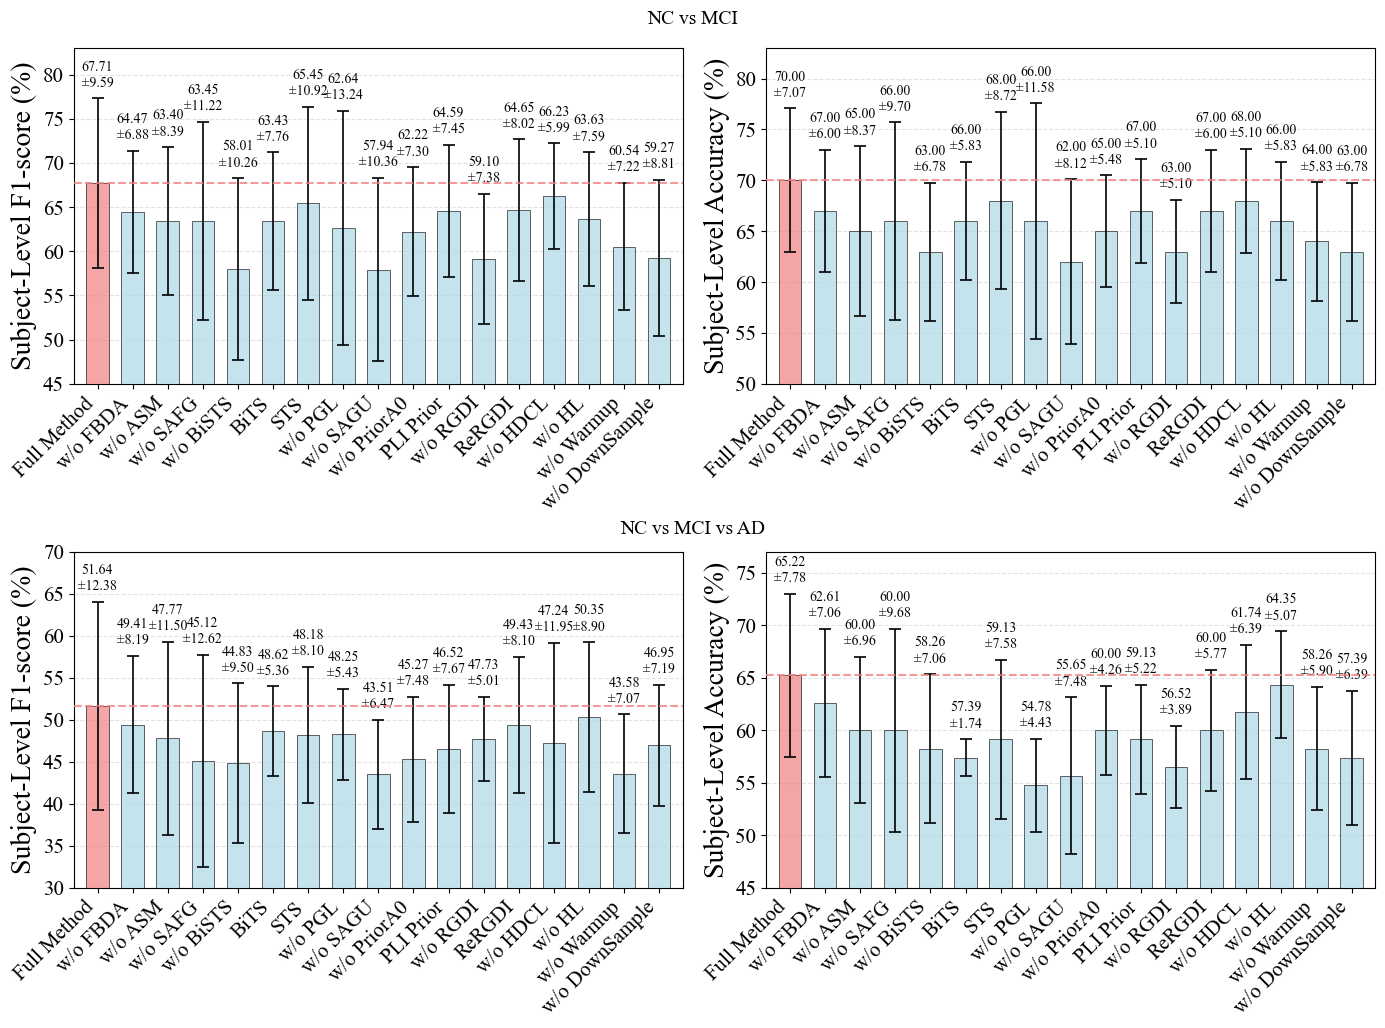

PosixPath('/root/autodl-tmp/ADSST-Net/figs/USTBMCI_ModelAblation_SubjectLevel_NCvsMCI_vs_NCvsMCIvsAD_panel.svg')

In [20]:
# 二分类 + 三分类 Subject-Level 模型消融 2×2 分面板
if "df_ablation" not in globals():
    df_ablation = load_model_ablation_results(EXCEL_PATH)

plot_subject_level_task_panel(
    df_ablation,
    SAVE_DIR,
    row_titles=("NC vs MCI", "NC vs MCI vs AD"),
    figsize=(14, 10),
    rotation=45,
    value_fmt=".2f",
    value_as_percent=True,
    # 字体大小（可按需调整）
    title_fontsize=14,
    ylabel_fontsize=20,   # 纵轴标题（指标名）
    xtick_fontsize=15,    # 横轴模块名刻度
    ytick_fontsize=15,    # 纵轴数值刻度
    value_fontsize=10,     # 柱顶 mean±std 标注
    hspace=0.5,          # 分面板间距
    # 柱间距与左右留白（与柱宽同一坐标单位，柱宽默认 0.72）
    bar_gap=0.4,            # 相邻柱之间的空白间隔，越大柱越疏
    bar_side_margin=0.4,    # 最左/最右柱外侧到左右边界的距离，越大两侧留白越多
    # 纵轴范围：按任务分别设置 F12 / Accuracy2（上限未指定时自动计算）
    metric_ymin_by_task={
        "NCvsMCI": {"F12 Mean": 45, "Accuracy2 Mean": 50},
        "NCvsMCIvsAD": {"F12 Mean": 30, "Accuracy2 Mean": 45},
    },
    metric_ymax_by_task={
        "NCvsMCI": {"F12 Mean": 83, "Accuracy2 Mean": 83},
        "NCvsMCIvsAD": {"F12 Mean": 70, "Accuracy2 Mean": 77},
    },
    # Full Model 基准虚线（可按需调整）
    baseline_linewidth=1.5,
    baseline_alpha=0.8,
)